# 时间衰减统计 + 逻辑回归

先运行 `02_features.ipynb` 和 `base_line.ipynb`。本 Notebook 读取它们的结果，不改 cleaned 或旧模型。

**输入**：cleaned 的预测样本、Matches 的完整有效历史、baseline_features 的共同信息。**输出**：时间加权特征、供下一本 LSTM 使用的逐场历史序列、验证/测试分数、逐场概率和模型。

近期仍恰好5场；交锋仍全部此前记录。每条历史权重为 `2**(-距本场天数/半衰期)`，加权统计为 `sum(w*x)/sum(w)`。近期半衰期固定90天、交锋365天，属于第一版预先设定，未搜索最优衰减速度。归一化权重只改变历史之间的相对权重；只有一次交锋时其权重仍为1，不代表久远的唯一交锋可靠。

B不变：联赛、Elo差、交锋次数、无交锋标记。F/H仍各3个统计，仅将普通平均改成加权平均。无交锋时H=0，由B标识缺失。分别训练赛果模型、赔率拟合模型和含赔率输入的增量模型。所有模型同一批比赛，训练≤2020，验证2021—22，测试2023—24；2025不评分。验证只选C，测试前保存选择。

历史只用严格早于比赛日的赛果，同日统一更新。2023—24已在旧分析中看过，本次是后续比较。

## 1. 环境和输入

In [1]:
from pathlib import Path
from collections import defaultdict, deque
import json
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/raw/Matches.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/Matches.csv').exists(), '请从项目根目录或notebooks目录运行。'
CORE = ['Division', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FTHome', 'FTAway', 'FTResult']
MISSING_TOKENS = {'', 'nan', 'na', 'n/a', 'null', 'none'}
FORM_COLUMNS = [f'Form{k}{side}' for side in ['Home', 'Away'] for k in [3, 5]]
COUNTRY = {d: d for d in 'ARG AUT BRA CHN DEN FIN IRL JAP MEX NOR POL ROM RUS SUI SWE USA'.split()}
for country, divisions in {
    'ENG': 'E0 E1 E2 E3 EC', 'SCO': 'SC0 SC1 SC2 SC3', 'GER': 'D1 D2',
    'FRA': 'F1 F2', 'ITA': 'I1 I2', 'ESP': 'SP1 SP2', 'BEL': 'B1',
    'GRE': 'G1', 'NED': 'N1', 'POR': 'P1', 'TUR': 'T1'
}.items():
    COUNTRY.update({d: country for d in divisions.split()})

def normalize(value):
    return ' '.join(unicodedata.normalize('NFKC', str(value)).split())



def read_raw(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    for col in frame:
        missing = frame[col].str.strip().str.lower().isin(MISSING_TOKENS)
        frame.loc[missing, col] = np.nan
    return frame
import warnings
from datetime import datetime, timezone
import joblib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 20261028
C_GRID = [0.01, 0.1, 1.0]
TRAIN_END = '2020-12-31'
VALID_END = '2022-12-31'
TEST_END = '2024-12-31'
CLASSES = ['H', 'D', 'A']
EPS = 1e-15
OUT = ROOT / 'reports/time_decay'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)

cleaned_path = ROOT / 'data/processed/cleaned.csv'
cleaned = pd.read_csv(cleaned_path, parse_dates=['MatchDate'])
assert cleaned.SourceRow.is_unique
assert cleaned[['HomeElo','AwayElo','Form5Home','Form5Away','OddHome','OddDraw','OddAway']].notna().all().all()
assert cleaned[['Form5HomeCount','Form5AwayCount']].eq(5).all().all()
assert np.isfinite(cleaned[['OddHome','OddDraw','OddAway']]).all().all()
assert cleaned[['OddHome','OddDraw','OddAway']].gt(1).all().all()
print('cleaned:', cleaned.shape)

cleaned: (133512, 46)


## 2. 从完整历史生成序列（旧→新）

In [2]:
def prepare_matches(raw):
    df = raw.copy()
    df.insert(0, 'SourceRow', np.arange(2, len(df) + 2))
    reasons = pd.Series('', index=df.index, dtype=object)
    missing = df[CORE].isna().any(axis=1)
    reasons.loc[missing] = 'missing_core_field'
    for col in ['Division', 'HomeTeam', 'AwayTeam']:
        df[col] = df[col].map(lambda v: normalize(v) if pd.notna(v) else v)
    day = pd.to_datetime(df.MatchDate, format='%Y-%m-%d', errors='coerce')
    reasons.loc[reasons.eq('') & day.isna()] = 'invalid_date'
    for col in ['FTHome', 'FTAway']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    scores = df[['FTHome', 'FTAway']]
    ok = np.isfinite(scores).all(axis=1) & scores.ge(0).all(axis=1) & scores.mod(1).eq(0).all(axis=1)
    expected = np.where(df.FTHome > df.FTAway, 'H', np.where(df.FTHome < df.FTAway, 'A', 'D'))
    reasons.loc[reasons.eq('') & ~ok] = 'invalid_score'
    reasons.loc[reasons.eq('') & df.FTResult.ne(expected)] = 'result_score_conflict'
    reasons.loc[reasons.eq('') & df.HomeTeam.eq(df.AwayTeam)] = 'same_home_and_away_team'
    excluded = raw.loc[reasons.ne('')].copy()
    excluded.insert(0, 'SourceRow', df.loc[reasons.ne(''), 'SourceRow'])
    excluded['Reason'] = reasons.loc[reasons.ne('')]
    df = df.loc[reasons.eq('')].copy()
    df['Country'] = df.Division.map(COUNTRY)
    if df.Country.isna().any():
        raise ValueError('发现未知联赛代码，需先补充国家映射。')
    df['MatchDate'] = day.loc[df.index]
    df[['FTHome', 'FTAway']] = df[['FTHome', 'FTAway']].astype(int)
    key = ['Division', 'MatchDate', 'HomeTeam', 'AwayTeam']
    if df.duplicated(key).any():
        raise ValueError('发现重复比赛，需核对后再生成，不自动合并。')
    df = df.sort_values(['MatchDate', 'SourceRow']).reset_index(drop=True)
    appearances = pd.concat([
        df[['Country', 'MatchDate', 'HomeTeam']].rename(columns={'HomeTeam': 'Team'}),
        df[['Country', 'MatchDate', 'AwayTeam']].rename(columns={'AwayTeam': 'Team'})])
    if appearances.duplicated(['Country', 'MatchDate', 'Team']).any():
        raise ValueError('发现同队同日多场记录，需核对后再生成。')
    return df, excluded
raw_matches = read_raw(ROOT / 'data/raw/Matches.csv')
valid_history, invalid_history = prepare_matches(raw_matches)
assert set(cleaned.SourceRow).issubset(set(valid_history.SourceRow))
print('有效历史比赛：', len(valid_history), '；核心信息无效：', len(invalid_history))

有效历史比赛： 230554 ；核心信息无效： 3


In [3]:
features = pd.read_csv(ROOT / 'data/processed/baseline_features.csv', parse_dates=['MatchDate'])
features = features.sort_values(['MatchDate','SourceRow']).reset_index(drop=True)
assert np.array_equal(features.SourceRow, cleaned.sort_values(['MatchDate','SourceRow']).SourceRow)
B = ['elo_diff','h2h_count','h2h_missing']
F = ['recent_ppg_diff','recent_gd_diff','recent_draw_rate_mean']
H = ['h2h_ppg_diff','h2h_gd','h2h_draw_rate']
Q = ['q_log_H_D','q_log_A_D']
HALF_F, HALF_H = 90., 365.

def build_sequences(history, targets):
    lookup = {int(r):i for i,r in enumerate(targets.SourceRow)}
    recent = defaultdict(lambda: deque(maxlen=5))
    pairs = defaultdict(list)
    recent_out = np.zeros((len(targets),2,5,4), dtype=np.float32)
    pair_out = [None]*len(targets)
    for day, batch in history.groupby('MatchDate', sort=True):
        ordinal = day.toordinal()
        for r in batch.itertuples():
            if r.SourceRow not in lookup:
                continue
            i = lookup[r.SourceRow]
            for side,team in enumerate([r.HomeTeam,r.AwayTeam]):
                records = np.array(recent[(r.Country,team)],dtype=np.float32)
                assert records.shape == (5,4), 'cleaned样本必须有完整5场历史'
                records[:,3] = ordinal-records[:,3]
                assert (records[:,3]>0).all()
                recent_out[i,side] = records
            first,second = sorted([r.HomeTeam,r.AwayTeam])
            records = np.array(pairs[(r.Country,first,second)],dtype=np.float32).reshape(-1,4)
            sign = 1 if r.HomeTeam==first else -1
            records[:,:2] *= sign
            records[:,3] = ordinal-records[:,3]
            assert (records[:,3]>0).all()
            pair_out[i] = records
        for r in batch.itertuples():
            hp = 3 if r.FTResult=='H' else 1 if r.FTResult=='D' else 0
            ap = 3 if r.FTResult=='A' else 1 if r.FTResult=='D' else 0
            gd,draw = r.FTHome-r.FTAway,int(r.FTResult=='D')
            recent[(r.Country,r.HomeTeam)].append((hp,gd,draw,ordinal))
            recent[(r.Country,r.AwayTeam)].append((ap,-gd,draw,ordinal))
            first,second = sorted([r.HomeTeam,r.AwayTeam])
            sign = 1 if r.HomeTeam==first else -1
            pairs[(r.Country,first,second)].append((sign*(hp-ap),sign*gd,draw,ordinal))
    assert all(x is not None for x in pair_out)
    lengths = np.array([len(x) for x in pair_out],dtype=np.int64)
    # 按实际最长序列补齐，绝不截去老交锋；长度只控制存储和mask，不作为调参依据。
    padded = np.zeros((len(targets), max(1,int(lengths.max())),4),dtype=np.float32)
    for i,records in enumerate(pair_out):
        padded[i,:len(records)] = records
    return recent_out,padded,lengths

recent_seq, h2h_seq, h2h_lengths = build_sequences(valid_history,features)
np.testing.assert_array_equal(h2h_lengths,features.h2h_count)
assert (recent_seq[:,:,:,3]>0).all()
print('近期序列:',recent_seq.shape,'交锋序列:',h2h_seq.shape,'无交锋:',int((h2h_lengths==0).sum()))

近期序列: (133512, 2, 5, 4) 交锋序列: (133512, 81, 4) 无交锋: 9351


## 3. 计算加权统计并保存历史序列

近期每条记录为积分、净胜球、平局标记、距本场天数；交锋每条记录为本场主队减客队的积分差、主队净胜球、平局标记、距本场天数。保存的序列供LSTM读取。

In [4]:
def weighted_stats(sequence,lengths,half_life):
    mask = np.arange(sequence.shape[1])[None,:] < np.asarray(lengths)[:,None]
    ages = sequence[:,:,3].astype(float)
    # 减最小年龄仅为防止下溢，与原式的归一化权重完全相同。
    youngest = np.where(mask,ages,np.inf).min(axis=1)
    youngest[~np.isfinite(youngest)] = 0
    logits = -np.log(2)*(ages-youngest[:,None])/half_life
    weights = np.exp(np.where(mask,logits,-np.inf))
    denominator = weights.sum(axis=1,keepdims=True)
    weights = np.divide(weights,denominator,out=np.zeros_like(weights),where=denominator>0)
    return (sequence[:,:,:3]*weights[:,:,None]).sum(axis=1)

def feature_statistics(half_f,half_h):
    home = weighted_stats(recent_seq[:,0],np.full(len(features),5),half_f)
    away = weighted_stats(recent_seq[:,1],np.full(len(features),5),half_f)
    pair = weighted_stats(h2h_seq,h2h_lengths,half_h)
    return np.column_stack([home[:,0]-away[:,0],home[:,1]-away[:,1],(home[:,2]+away[:,2])/2,pair])

cache = ROOT / 'data/processed/history_sequences.npz'
np.savez_compressed(cache,SourceRow=features.SourceRow.to_numpy(),recent=recent_seq,h2h=h2h_seq,h2h_lengths=h2h_lengths)
manifest = {'rows':len(features),'recent_window':5,'h2h':'all strictly earlier matches','fields':['points_or_points_difference','goal_difference','draw','age_days'],'recent_shape':list(recent_seq.shape),'h2h_shape':list(h2h_seq.shape),'half_life_recent_days':HALF_F,'half_life_h2h_days':HALF_H}
(ROOT/'data/processed/history_sequences.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
features[F+H] = feature_statistics(HALF_F,HALF_H)
features.to_csv(ROOT/'data/processed/time_decay_features.csv',index=False)
train = features.loc[features.split.eq('train')].reset_index(drop=True)
validation = features.loc[features.split.eq('validation')].reset_index(drop=True)
test = features.loc[features.split.eq('test')].reset_index(drop=True)
assert train.MatchDate.max()<validation.MatchDate.min() and validation.MatchDate.max()<test.MatchDate.min()
print('训练/验证/测试：',len(train),len(validation),len(test))

训练/验证/测试： 106288 12598 11772


## 4. 模型定义与验证集选择

In [5]:
def normalize_probabilities(p):
    p = np.asarray(p, dtype=float)
    assert p.ndim == 2 and p.shape[1] == 3 and np.isfinite(p).all()
    assert (p >= 0).all() and np.allclose(p.sum(axis=1), 1, atol=1e-8)
    p = np.clip(p, EPS, 1)
    return p / p.sum(axis=1, keepdims=True)


def match_losses(frame, probabilities):
    p = normalize_probabilities(probabilities)
    target_q = frame[['q_H','q_D','q_A']].to_numpy(float)
    y = frame.y.to_numpy(int)
    one_hot = np.eye(3)[y]
    return {
        'log_loss': -np.log(p[np.arange(len(frame)),y]),
        'brier': np.square(p-one_hot).sum(axis=1),
        'accuracy': (p.argmax(axis=1)==y).astype(float),
        'kl_to_odds': np.sum(target_q * (np.log(target_q)-np.log(p)), axis=1),
        'odds_probability_mae': np.abs(target_q-p).mean(axis=1),
    }


def fit_classifier(X, frame, target, C):
    if target == 'odds':
        train_X = np.repeat(X,3,axis=0)
        train_y = np.tile(np.arange(3),len(frame))
        weights = frame[['q_H','q_D','q_A']].to_numpy(float).ravel()
        assert np.isclose(weights.sum(),len(frame))
    else:
        train_X, train_y, weights = X, frame.y.to_numpy(int), None
    for max_iter in [2000,10000]:
        model = LogisticRegression(C=C,l1_ratio=0,solver='lbfgs',tol=1e-7,
                                   max_iter=max_iter,random_state=SEED)
        with warnings.catch_warnings(record=True) as seen, threadpool_limits(limits=1):
            warnings.simplefilter('always',ConvergenceWarning)
            model.fit(train_X,train_y,sample_weight=weights)
        convergence_warning = any(issubclass(w.category,ConvergenceWarning) for w in seen)
        if not convergence_warning and model.n_iter_.max() < max_iter:
            assert np.array_equal(model.classes_,[0,1,2])
            return model
    raise RuntimeError('逻辑回归未收敛，停止生成结果。')


def make_preprocessor(columns, include_division=True):
    transformers = [('numeric',StandardScaler(),columns)]
    if include_division:
        transformers.append(('division',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['Division']))
    return ColumnTransformer(transformers,remainder='drop',sparse_threshold=0)




def unseen_divisions(preprocessor, frame, include_division):
    if not include_division:
        return 0
    known = set(preprocessor.named_transformers_['division'].categories_[0])
    return int((~frame.Division.isin(known)).sum())

In [6]:
specs = {}
for suffix,extra in [('1',F),('2',H),('3',F+H)]:
    specs['TD_M'+suffix] = {'target':'outcome','columns':B+extra,'division':True,'group':'outcome'}
    specs['TD_O'+suffix] = {'target':'odds','columns':B+extra,'division':True,'group':'odds_fit'}
    specs['TD_Q'+suffix] = {'target':'outcome','columns':B+Q+extra,'division':True,'group':'odds_increment'}
model_order = list(specs)
pd.DataFrame([{'model':n,'target':s['target'],'inputs':', '.join(['Division']+s['columns'])} for n,s in specs.items()]).to_csv(OUT/'model_inputs.csv',index=False)
selected,validation_rows = {},[]
for name,spec in specs.items():
    prep = make_preprocessor(spec['columns'])
    X_train,X_validation = prep.fit_transform(train),None
    X_validation = prep.transform(validation)
    candidates=[]
    for C in C_GRID:
        estimator=fit_classifier(X_train,train,spec['target'],C)
        with threadpool_limits(limits=1):
            p=estimator.predict_proba(X_validation)
        score=match_losses(validation,p)['kl_to_odds' if spec['target']=='odds' else 'log_loss'].mean()
        candidates.append((float(score),C))
        validation_rows.append({'model':name,'C':C,'score':float(score)})
    score,C=min(candidates)
    selected[name]={'C':C,'validation_score':score}
    print(name,selected[name],flush=True)
pd.DataFrame(validation_rows).to_csv(OUT/'validation_scores.csv',index=False)
selection={'selected':selected,'frozen_utc':datetime.now(timezone.utc).isoformat(),'half_life_recent_days':HALF_F,'half_life_h2h_days':HALF_H,'C_grid':C_GRID,'specs':specs,'note':'Half-lives fixed in advance; not validated as optimal.'}
(OUT/'selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')

TD_M1 {'C': 0.01, 'validation_score': 1.0176660310719101}


TD_O1 {'C': 0.01, 'validation_score': 0.013939437442528289}


TD_Q1 {'C': 0.01, 'validation_score': 0.9972104659251484}


TD_M2 {'C': 0.01, 'validation_score': 1.0185807644682587}


TD_O2 {'C': 0.01, 'validation_score': 0.014692156700541404}


TD_Q2 {'C': 0.01, 'validation_score': 0.9974297777621957}


TD_M3 {'C': 0.01, 'validation_score': 1.0177640906359897}


TD_O3 {'C': 0.01, 'validation_score': 0.013806728175346386}


TD_Q3 {'C': 0.01, 'validation_score': 0.9973423753056831}


3791

## 5. 截至2022年重训，预测相同测试比赛

In [7]:
assert json.loads((OUT/'selection.json').read_text())['selected']==selected
final_train=pd.concat([train,validation],ignore_index=True)
predictions={}
for name,spec in specs.items():
    prep=make_preprocessor(spec['columns'])
    X=prep.fit_transform(final_train)
    estimator=fit_classifier(X,final_train,spec['target'],selected[name]['C'])
    with threadpool_limits(limits=1):
        predictions[name]=normalize_probabilities(estimator.predict_proba(prep.transform(test)))
    joblib.dump({'preprocessor':prep,'model':estimator,'spec':spec,'C':selected[name]['C'],'classes':CLASSES,'train_end':VALID_END},OUT/'models'/f'{name}.joblib')
    print(name, 'done',flush=True)
old_predictions=pd.read_csv(ROOT/'reports/baseline/test_predictions.csv')
for name,part in old_predictions.groupby('model',sort=False):
    part=part.set_index('SourceRow').loc[test.SourceRow]
    np.testing.assert_array_equal(part.y,test.y)
    predictions[name]=normalize_probabilities(part[['p_H','p_D','p_A']].to_numpy())
loss_arrays={name:match_losses(test,p) for name,p in predictions.items()}
scores=pd.DataFrame([{'model':name,'matches':len(test),**{k:float(v.mean()) for k,v in a.items()}} for name,a in loss_arrays.items()])
scores.to_csv(OUT/'test_scores.csv',index=False)
parts=[]
for name in model_order:
    p=predictions[name]
    part=test[['SourceRow','MatchDate','Division','HomeTeam','AwayTeam','y','q_H','q_D','q_A']].copy()
    part['model']=name
    part[['p_H','p_D','p_A']]=p
    parts.append(part)
pd.concat(parts,ignore_index=True).to_csv(OUT/'test_predictions.csv',index=False)
pd.DataFrame([{'year':int(year),'model':name,**{k:float(v[test.year.eq(year)].mean()) for k,v in a.items()}} for year in sorted(test.year.unique()) for name,a in loss_arrays.items()]).to_csv(OUT/'test_scores_by_year.csv',index=False)
display(scores)

TD_M1 done


TD_O1 done


TD_Q1 done


TD_M2 done


TD_O2 done


TD_Q2 done


TD_M3 done


TD_O3 done


TD_Q3 done


,model,matches,log_loss,brier,accuracy,kl_to_odds,odds_probability_mae
0,TD_M1,11772,1.002421,0.599169,0.501104,1.398391e-02,3.962942e-02
1,TD_O1,11772,1.003116,0.599661,0.503568,1.231654e-02,3.778855e-02
2,TD_Q1,11772,0.986328,0.588593,0.520048,1.350213e-03,1.264621e-02
3,TD_M2,11772,1.003141,0.599664,0.504077,1.458538e-02,4.027676e-02
4,TD_O2,11772,1.003789,0.600130,0.505182,1.304098e-02,3.850634e-02
5,TD_Q2,11772,0.986383,0.588605,0.519963,1.171341e-03,1.173132e-02
6,TD_M3,11772,1.002407,0.599144,0.502379,1.395959e-02,3.963138e-02
7,TD_O3,11772,1.003082,0.599638,0.503568,1.224526e-02,3.769730e-02
8,TD_Q3,11772,0.986317,0.588568,0.519368,1.382126e-03,1.280660e-02
9,M0,11772,1.003156,0.599690,0.502718,1.459227e-02,4.026439e-02


## 6. 同场配对比较和与赔率的相关性

In [ ]:
rng = np.random.default_rng(SEED)
block_weights = []
blocks = []
for year in sorted(test.year.unique()):
    ids = np.flatnonzero(test.year.eq(year).to_numpy())
    day_index = (test.loc[ids,'MatchDate'] - pd.Timestamp(f'{int(year)}-01-01')).dt.days.to_numpy()
    group_id = day_index // 28
    year_blocks = [ids[group_id==group] for group in np.unique(group_id)]
    n_blocks = len(year_blocks)
    draws = rng.integers(0,n_blocks,size=(1000,n_blocks))
    counts = np.zeros((1000,n_blocks),dtype=int)
    for j in range(n_blocks):
        counts[:,j] = (draws==j).sum(axis=1)
    block_weights.append(counts)
    blocks.extend(year_blocks)
weights = np.concatenate(block_weights,axis=1)
block_sizes = np.array([len(ids) for ids in blocks])
bootstrap_denominator = weights @ block_sizes

def paired_difference(left, right, metric):
    difference = loss_arrays[left][metric] - loss_arrays[right][metric]
    sums = np.array([difference[ids].sum() for ids in blocks])
    bootstrap = weights @ sums / bootstrap_denominator
    low, high = np.quantile(bootstrap,[.025,.975])
    return {'left':left,'right':right,'metric':metric,'difference':float(difference.mean()),
            'ci_low':float(low),'ci_high':float(high),'ci_includes_zero':bool(low<=0<=high)}


comparisons=[]
for group,metric in [('M','log_loss'),('O','kl_to_odds'),('Q','log_loss')]:
    for k in ['1','2','3']:
        comparisons.append(('TD_'+group+k,group+k,metric))
        comparisons.append(('TD_'+group+k,group+'0',metric))
    comparisons.append(('TD_'+group+'1','TD_'+group+'2',metric))
    comparisons.append(('TD_'+group+'3','TD_'+group+'1',metric))
    comparisons.append(('TD_'+group+'3','TD_'+group+'2',metric))
comparisons.extend([
    ("M1", "M2", "kl_to_odds"),
    ("M3", "M1", "kl_to_odds"),
    ("TD_M1", "TD_M2", "kl_to_odds"),
    ("TD_M3", "TD_M1", "kl_to_odds"),
    ("TD_M1", "M1", "kl_to_odds"),
    ("TD_M2", "M2", "kl_to_odds"),
])
paired=pd.DataFrame([paired_difference(*x) for x in comparisons])
paired.to_csv(OUT/'paired_comparisons.csv',index=False)
correlations=[]
for col in F+H:
    target=test.q_D if 'draw' in col else test.q_H-test.q_A
    correlations.append({'feature':col,'target':'q_D' if 'draw' in col else 'q_H-q_A','spearman':float(spearmanr(test[col],target).statistic)})
pd.DataFrame(correlations).to_csv(OUT/'odds_correlations.csv',index=False)
display(paired)

,left,right,metric,difference,ci_low,ci_high,ci_includes_zero
0,TD_M1,M1,log_loss,-0.000175,-0.000283,-0.000069,False
1,TD_M1,M0,log_loss,-0.000736,-0.001516,0.000022,True
2,TD_M2,M2,log_loss,-0.000018,-0.000250,0.000253,True
3,TD_M2,M0,log_loss,-0.000015,-0.000232,0.000188,True
4,TD_M3,M3,log_loss,-0.000176,-0.000415,0.000075,True
5,TD_M3,M0,log_loss,-0.000749,-0.001638,0.000077,True
6,TD_M1,TD_M2,log_loss,-0.000720,-0.001470,0.000016,True
7,TD_M3,TD_M1,log_loss,-0.000013,-0.000226,0.000199,True
8,TD_M3,TD_M2,log_loss,-0.000734,-0.001523,0.000013,True
9,TD_O1,O1,kl_to_odds,-0.000061,-0.000109,-0.000026,False


## 7. 保存结果报告

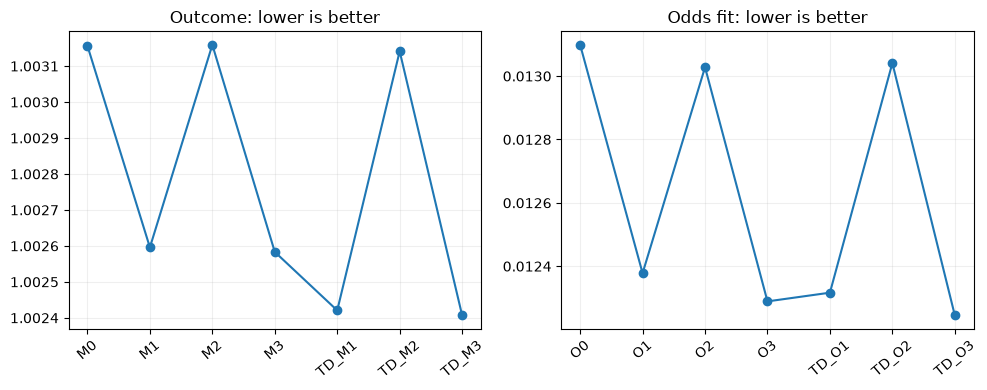

完成： /home/euan_li/projects/AML/reports/time_decay/RESULTS.zh-CN.md


In [9]:
def md_table(frame):
    columns = list(frame.columns)
    lines = ['| '+' | '.join(columns)+' |','| '+' | '.join(['---']*len(columns))+' |']
    for record in frame.itertuples(index=False,name=None):
        values = [f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v) for v in record]
        lines.append('| '+' | '.join(values)+' |')
    return '\n'.join(lines)



report = '# 时间衰减逻辑回归：实际运行结果\n\n'
report += '近期固定5场（半衰期90天），交锋全部历史（365天）；半衰期是预先固定的初始设置，不代表最优。B及样本与旧baseline相同。\n\n'
report += 'TD_M1=B+近期，TD_M2=B+交锋，TD_M3=B+两者，输出赛果H/D/A概率。TD_O系列输入相同、训练目标为赔率概率；TD_Q系列另加两个赔率对数比，输出赛果概率。旧M/O/Q模型仅载入已保存预测。\n\n'
report += f'训练{len(train)}场，验证{len(validation)}场，测试{len(test)}场。验证选C后，在截至2022年的{len(final_train)}场重训；2023—24仅预测，2025不参与。\n\n'
report += md_table(scores[['model','log_loss','brier','accuracy','kl_to_odds']])
report += '\n\n## 与普通平均相比\n\n'
report += md_table(paired.loc[paired.right.isin(['M1','M2','M3','O1','O2','O3','Q1','Q2','Q3'])])
report += '\n\n差值=左−右；损失差为负表示左边好。区间来自按年分层的28天块bootstrap（1000次）；跨0不能说稳定改善。区间未包含训练和调参不确定性，也未校正多重比较。赔率拟合好不等于真实赛果预测好。\n\n'
report += '历史序列来自全部有效原始赛果，只使用严格早于比赛日的记录，供下一本LSTM读取。\n'
(OUT/'RESULTS.zh-CN.md').write_text(report,encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,names,metric,title in [(axes[0],['M0','M1','M2','M3','TD_M1','TD_M2','TD_M3'],'log_loss','Outcome: lower is better'),(axes[1],['O0','O1','O2','O3','TD_O1','TD_O2','TD_O3'],'kl_to_odds','Odds fit: lower is better')]:
    values=scores.set_index('model').loc[names,metric]
    ax.plot(names,values,'o-');ax.set_title(title);ax.tick_params(axis='x',rotation=40);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=160);plt.show()
print('完成：',OUT/'RESULTS.zh-CN.md')

## 8. M模型预测概率与赔率市场比较

读取已保存的预测文件，计算KL、MAE、Pearson、Spearman和配对时间块Bootstrap，不重新训练。

In [10]:
# ==========================================
# NEW EXPERIMENT: Time-decay M models vs Betting Market
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

# 1. 读取已经保存的预测结果
ROOT = Path.cwd()
if not (ROOT / "reports/baseline/test_predictions.csv").exists():
    ROOT = ROOT.parent

OUT = ROOT / "reports/time_decay"
path = OUT / "test_predictions.csv"
base_path = ROOT / "reports/baseline/test_predictions.csv"
assert path.exists() and base_path.exists(), "请先生成 baseline 和时间衰减模型的预测文件。"

base_raw = pd.read_csv(base_path, parse_dates=["MatchDate"])
decay_raw = pd.read_csv(path, parse_dates=["MatchDate"])
models = ["M0", "TD_M1", "TD_M2", "TD_M3"]
raw = pd.concat([base_raw.loc[base_raw.model.eq("M0")],
                 decay_raw.loc[decay_raw.model.isin(models[1:])]], ignore_index=True)

# 统一比赛顺序，确保每个模型比较的是同一批比赛
ref = (
    raw.loc[raw.model.eq("M0")]
    .sort_values(["MatchDate", "SourceRow"])
    .reset_index(drop=True)
)
assert len(ref) > 0 and ref.SourceRow.is_unique

# 用共同测试样本和原始普通赔率独立核对身份、赛果和市场概率。
features = pd.read_csv(ROOT / "data/processed/baseline_features.csv", parse_dates=["MatchDate"])
expected = features.loc[features.split.eq("test")].sort_values(["MatchDate", "SourceRow"]).reset_index(drop=True)
if not expected.SourceRow.is_unique or len(ref) != len(expected):
    raise ValueError("预测与测试样本数量不一致，或比赛行号有重复。")
np.testing.assert_array_equal(ref.SourceRow, expected.SourceRow)
for col in ["MatchDate", "Division", "HomeTeam", "AwayTeam", "y"]:
    np.testing.assert_array_equal(ref[col].to_numpy(), expected[col].to_numpy())
cleaned = pd.read_csv(ROOT / "data/processed/cleaned.csv").set_index("SourceRow")
source = cleaned.loc[ref.SourceRow]
np.testing.assert_array_equal(source.FTResult.map({"H": 0, "D": 1, "A": 2}), ref.y)
odds = source[["OddHome", "OddDraw", "OddAway"]].to_numpy(float)
if not np.isfinite(odds).all() or not (odds > 1).all():
    raise ValueError("发现无效赔率，无法计算市场概率。")
q_from_odds = 1 / odds
q_from_odds /= q_from_odds.sum(axis=1, keepdims=True)

# 博彩赔率转换后的三个概率
q = ref[["q_H", "q_D", "q_A"]].to_numpy(float)
assert np.isfinite(q).all() and (q > 0).all()
np.testing.assert_allclose(q.sum(axis=1), 1, rtol=0, atol=1e-10)
np.testing.assert_allclose(q, q_from_odds, rtol=0, atol=1e-12)

losses = {}
score_rows = []
corr_rows = []

# 2. 比较每个M模型输出与市场概率
for name in models:
    part = raw.loc[raw.model.eq(name)]
    if not part.SourceRow.is_unique or len(part) != len(ref) or set(part.SourceRow) != set(ref.SourceRow):
        raise ValueError(f"{name}的比赛行号与共同测试样本不一致。")
    rows = part.set_index("SourceRow").loc[ref.SourceRow]
    for col in ["MatchDate", "Division", "HomeTeam", "AwayTeam", "y"]:
        np.testing.assert_array_equal(rows[col].to_numpy(), ref[col].to_numpy())

    assert rows[["p_H", "p_D", "p_A", "q_H", "q_D", "q_A"]].notna().all().all()
    np.testing.assert_allclose(
        rows[["q_H", "q_D", "q_A"]].to_numpy(float), q, rtol=0, atol=1e-12
    )

    p = rows[["p_H", "p_D", "p_A"]].to_numpy(float)
    assert np.isfinite(p).all() and (p >= 0).all()
    np.testing.assert_allclose(p.sum(axis=1), 1, rtol=0, atol=1e-10)

    p = np.clip(p, 1e-15, 1)
    p = p / p.sum(axis=1, keepdims=True)

    # KL(q || p)：市场概率和M模型概率的差异
    kl_each = np.sum(q * (np.log(q) - np.log(p)), axis=1)

    # 平均绝对概率误差
    mae_each = np.mean(np.abs(q - p), axis=1)

    losses[name] = kl_each

    score_rows.append({
        "model": name,
        "matches": len(ref),
        "kl_to_odds": kl_each.mean(),
        "odds_probability_mae": mae_each.mean()
    })

    # 分别研究主胜、平局、客胜概率的相关性
    for k, outcome in enumerate(["H", "D", "A"]):
        corr_rows.append({
            "model": name,
            "outcome": outcome,
            "pearson_r": pearsonr(p[:, k], q[:, k]).statistic,
            "spearman_rho": spearmanr(p[:, k], q[:, k]).statistic
        })

scores_m = pd.DataFrame(score_rows)
corr_m = pd.DataFrame(corr_rows)
if not np.isfinite(corr_m[["pearson_r", "spearman_rho"]]).all().all():
    raise ValueError("概率列没有变化或包含无效值，无法计算相关系数。")
# 本实验复用已保存预测；核对原有分数表中的KL与MAE。
existing_scores = pd.read_csv(OUT / "test_scores.csv").set_index("model").loc[models]
np.testing.assert_allclose(
    scores_m.set_index("model").loc[models, ["kl_to_odds", "odds_probability_mae"]],
    existing_scores[["kl_to_odds", "odds_probability_mae"]], rtol=0, atol=1e-12
)

# 3. Bootstrap：比较不同M模型的KL差异
# 与原baseline一致：按年份分层，每28天为一个时间块
rng = np.random.default_rng(20261028)
blocks = []
count_parts = []

for year in sorted(ref.MatchDate.dt.year.unique()):
    ids = np.flatnonzero(ref.MatchDate.dt.year.eq(year).to_numpy())
    day = (
        ref.loc[ids, "MatchDate"] - pd.Timestamp(f"{year}-01-01")
    ).dt.days.to_numpy()

    block_id = day // 28
    year_blocks = [ids[block_id == b] for b in np.unique(block_id)]
    blocks.extend(year_blocks)

    n = len(year_blocks)
    sampled = rng.integers(0, n, size=(1000, n))
    counts = np.stack(
        [(sampled == j).sum(axis=1) for j in range(n)], axis=1
    )
    count_parts.append(counts)

weights = np.concatenate(count_parts, axis=1)
block_sizes = np.array([len(b) for b in blocks])
denominator = weights @ block_sizes

pairs = [
    ("TD_M1", "TD_M2"),
    ("TD_M1", "M0"),
    ("TD_M2", "M0"),
    ("TD_M3", "TD_M1"),
    ("TD_M3", "TD_M2")
]

comparison_rows = []

for left, right in pairs:
    difference = losses[left] - losses[right]
    block_sums = np.array([difference[b].sum() for b in blocks])
    bootstrap = (weights @ block_sums) / denominator

    low, high = np.quantile(bootstrap, [0.025, 0.975])

    comparison_rows.append({
        "left": left,
        "right": right,
        "kl_difference": difference.mean(),
        "ci_low": low,
        "ci_high": high,
        "ci_includes_zero": bool(low <= 0 <= high)
    })

comparisons_m = pd.DataFrame(comparison_rows)

# 4. 保存新实验结果
scores_m.to_csv(OUT / "m_vs_market_scores.csv", index=False)
corr_m.to_csv(OUT / "m_vs_market_correlations.csv", index=False)
comparisons_m.to_csv(OUT / "m_vs_market_comparisons.csv", index=False)

print("=== 1. M模型与赔率概率的KL/MAE ===")
display(scores_m)

print("=== 2. M模型与赔率概率的相关性 ===")
display(corr_m)

print("=== 3. KL差异与95% Bootstrap置信区间 ===")
display(comparisons_m)

print("实验完成，结果已保存至：", OUT)


# 在原报告后追加本实验，重复运行时只更新本实验的内容。
def market_table(frame):
    lines = ["| " + " | ".join(frame.columns) + " |",
             "| " + " | ".join(["---"] * len(frame.columns)) + " |"]
    for record in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(f"{v:.6f}" if isinstance(v, (float, np.floating)) else str(v) for v in record) + " |")
    return "\n".join(lines)

ref_m1, ref_m2 = models[1], models[2]
pair = comparisons_m.loc[comparisons_m.left.eq(ref_m1) & comparisons_m.right.eq(ref_m2)].iloc[0]
interpretation = ("区间全部小于0，在当前测试样本中近期模型更接近市场。" if pair.ci_high < 0
                  else "区间全部大于0，在当前测试样本中交锋模型更接近市场。" if pair.ci_low > 0
                  else "区间跨0，当前测试样本中差异不明确。")
section = "## M模型预测概率与市场隐含概率的对比\n\n"
section += f"比较{len(ref):,}场相同测试比赛，主胜、平局、客胜的M模型概率与普通赔率倒数归一化后的市场概率q。M模型按真实赛果训练；这里赔率仅用于测试期比较，不作为M模型输入。\n\n"
section += "KL(q||p)越低、三类平均绝对概率误差MAE越低，预测概率越接近市场。MAE的0.01对应平均1个百分点，属于各类别、各比赛绝对误差的平均。\n\n"
section += market_table(scores_m) + "\n\n"
section += "Pearson衡量数值线性相关，Spearman衡量排序相关；逐类别计算，相关性高不保证概率绝对值接近，也不能证明市场使用了哪些信息。\n\n"
section += market_table(corr_m) + "\n\n"
section += "以下差值为左模型KL减右模型KL；负数表示左边更接近市场。区间采用每年独立分层、28天时间块的1000次配对bootstrap，逐项描述测试样本波动，不包含重新训练和选参不确定性，未做多重比较校正。Pearson和Spearman这里只报告点估计。\n\n"
section += market_table(comparisons_m) + "\n\n"
section += f"{ref_m1}−{ref_m2}的KL差为{pair.kl_difference:.6f}，区间[{pair.ci_low:.6f}, {pair.ci_high:.6f}]；{interpretation}这比较的是赛果模型输出与市场的相似程度，不能直接解释为赛果预测更准，也不能认定市场实际使用近期或交锋信息。\n\n"
section += "所用比赛均为同一测试集；预测数据按SourceRow、日期、球队、联赛和赛果对齐，市场概率由cleaned.csv中三项有效赔率重新计算。历史特征和测试预测沿用此前生成的文件，历史只使用更早日期；原始已有Elo及赔率的具体记录时点无法仅凭这些文件独立确认。测试年份曾用于此前分析，这不是全新的独立测试。\n\n"
section += "完整结果分别见m_vs_market_scores.csv、m_vs_market_correlations.csv和m_vs_market_comparisons.csv。\n"
report_path = OUT / "RESULTS.zh-CN.md"
existing = report_path.read_text(encoding="utf-8")
start_marker = "<!-- m_vs_market:start -->"
end_marker = "<!-- m_vs_market:end -->"
if (start_marker in existing) != (end_marker in existing):
    raise ValueError("报告实验标记不完整，停止写入以保留现有内容。")
block = start_marker + "\n" + section + end_marker
if start_marker in existing:
    start = existing.index(start_marker)
    end = existing.index(end_marker, start) + len(end_marker)
    existing = existing[:start] + block + existing[end:]
else:
    existing = existing.rstrip() + "\n\n" + block + "\n"
_ = report_path.write_text(existing, encoding="utf-8")


=== 1. M模型与赔率概率的KL/MAE ===


,model,matches,kl_to_odds,odds_probability_mae
0,M0,11772,0.014592,0.040264
1,TD_M1,11772,0.013984,0.039629
2,TD_M2,11772,0.014585,0.040277
3,TD_M3,11772,0.013960,0.039631


=== 2. M模型与赔率概率的相关性 ===


,model,outcome,pearson_r,spearman_rho
0,M0,H,0.907528,0.882294
1,M0,D,0.815902,0.720077
2,M0,A,0.904347,0.876896
3,TD_M1,H,0.912789,0.889310
4,TD_M1,D,0.819729,0.723820
5,TD_M1,A,0.909844,0.884002
6,TD_M2,H,0.907600,0.882329
7,TD_M2,D,0.814985,0.718750
8,TD_M2,A,0.904677,0.877149
9,TD_M3,H,0.913024,0.889571


=== 3. KL差异与95% Bootstrap置信区间 ===


,left,right,kl_difference,ci_low,ci_high,ci_includes_zero
0,TD_M1,TD_M2,-0.000601,-0.000717,-0.000486,False
1,TD_M1,M0,-0.000608,-0.000728,-0.000490,False
2,TD_M2,M0,-0.000007,-0.000040,0.000032,True
3,TD_M3,TD_M1,-0.000024,-0.000056,0.000014,True
4,TD_M3,TD_M2,-0.000626,-0.000743,-0.000511,False


实验完成，结果已保存至： /home/euan_li/projects/AML/reports/time_decay
